In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv("iris.csv")
display(df.head())

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Data types:")
print(df.dtypes)
display(df.describe(include="all"))

Shape: (150, 5)
Columns: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
Data types:
sepal_length    float64
sepal_width     float64
petal_length    float64
petal_width     float64
species          object
dtype: object


,sepal_length,sepal_width,petal_length,petal_width,species
count,150.000000,150.000000,150.000000,150.000000,150
unique,NaN,NaN,NaN,NaN,3
top,NaN,NaN,NaN,NaN,setosa
freq,NaN,NaN,NaN,NaN,50
mean,5.843333,3.057333,3.758000,1.199333,NaN
std,0.828066,0.435866,1.765298,0.762238,NaN
min,4.300000,2.000000,1.000000,0.100000,NaN
25%,5.100000,2.800000,1.600000,0.300000,NaN
50%,5.800000,3.000000,4.350000,1.300000,NaN
75%,6.400000,3.300000,5.100000,1.800000,NaN


In [5]:
print("Missing values:\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Class distribution:\n", df["species"].value_counts())

Missing values:
 sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64
Duplicate rows: 1
Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


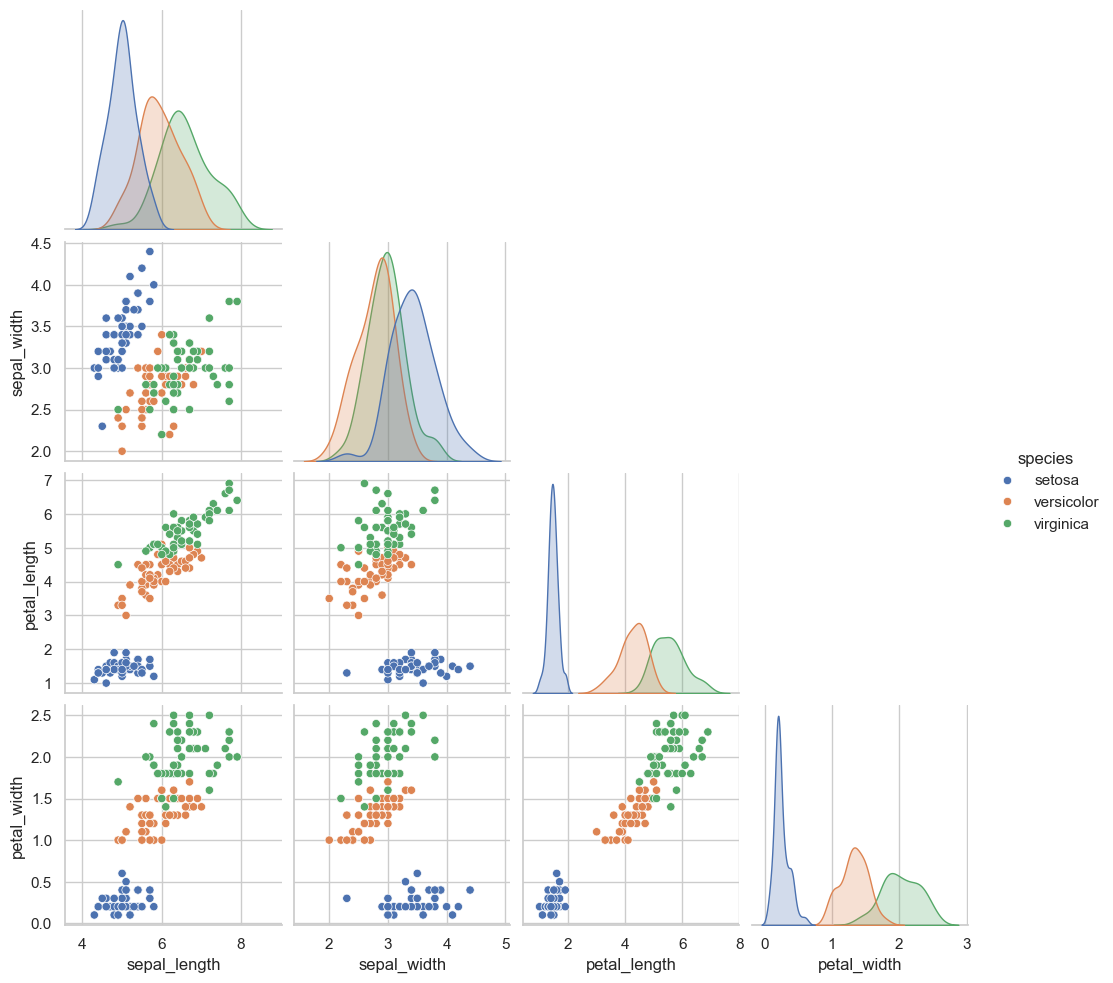

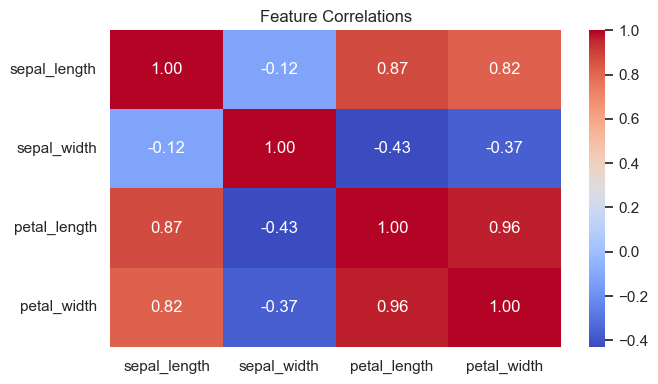

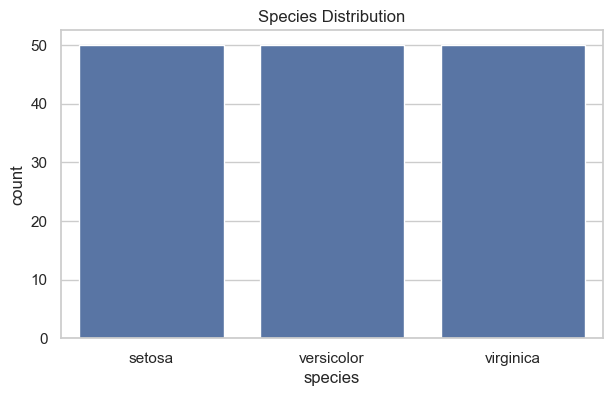

In [6]:
sns.pairplot(df, hue="species", corner=True)
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(df.drop(columns="species").corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=ax)
ax.set_title("Feature Correlations")
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x="species", ax=ax)
ax.set_title("Species Distribution")
plt.show()

In [7]:
X = df.drop(columns="species")
y = df["species"]
print("X:", X.shape, "y:", y.shape)

X: (150, 4) y: (150,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Training:", X_train.shape, "Testing:", X_test.shape)

Training: (120, 4) Testing: (30, 4)


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Training means after scaling:", X_train_scaled.mean(axis=0).round(3))

Training means after scaling: [-0.  0.  0.  0.]


In [10]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)

In [11]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X_train, y_train)
tree_pred = tree_model.predict(X_test)

In [12]:
predictions = {"Logistic Regression": log_pred, "Decision Tree": tree_pred}
metrics_rows = []
for name, y_pred in predictions.items():
    metrics_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1 (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })
    print(f"\n{name} classification report:\n")
    print(classification_report(y_test, y_pred, zero_division=0))
results_df = pd.DataFrame(metrics_rows)
display(results_df.round(4))


Logistic Regression classification report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree classification report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



,Model,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


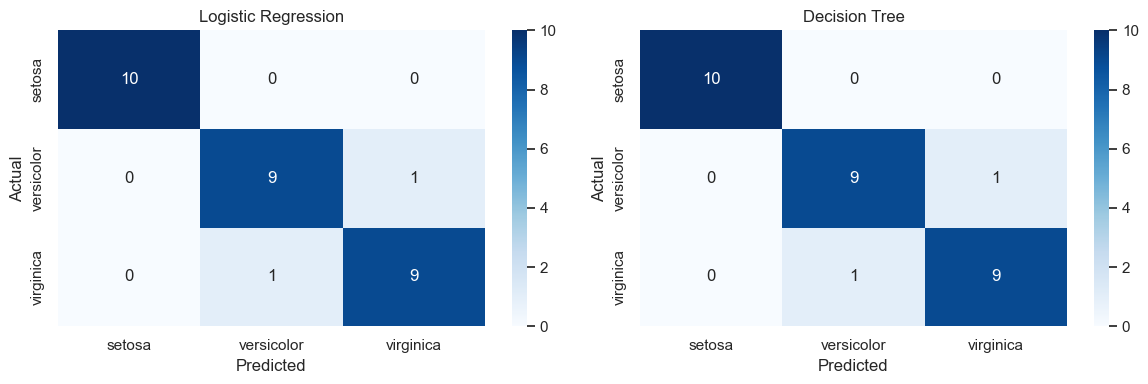

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=sorted(y.unique()), yticklabels=sorted(y.unique()), ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

C:\Users\rohan bhowmik\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


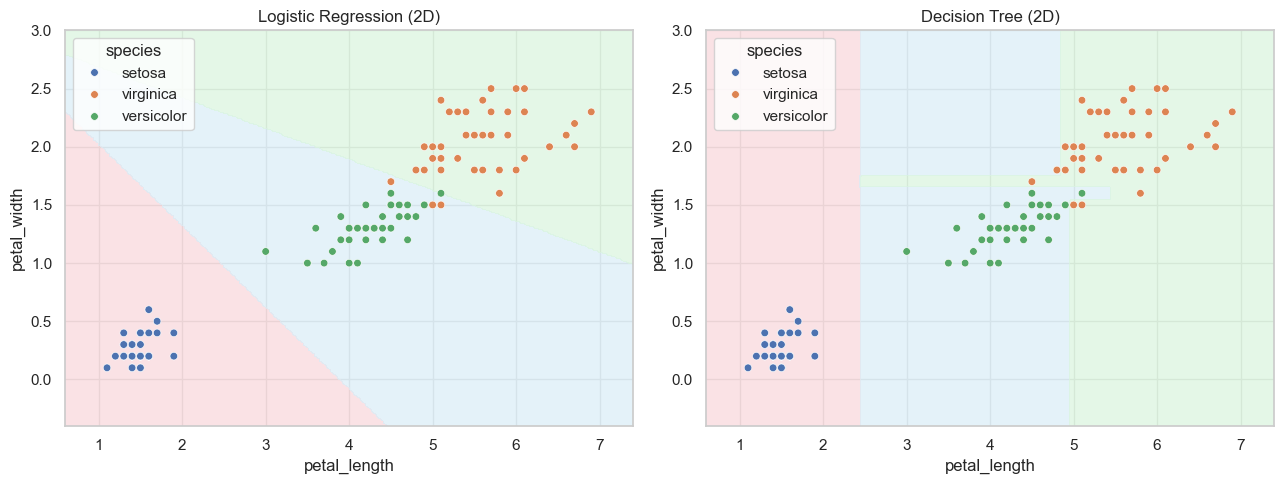

In [14]:
from matplotlib.colors import ListedColormap
features_2d = ["petal_length", "petal_width"]
X2_train = X_train[features_2d]
y2_train = y_train
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
plot_models = {
    "Logistic Regression (2D)": (LogisticRegression(max_iter=1000, random_state=42), X2_train_scaled, scaler2),
    "Decision Tree (2D)": (DecisionTreeClassifier(random_state=42), X2_train.values, None)
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
classes = sorted(y.unique())
colors = ListedColormap(["#f8d7da", "#d9edf7", "#d9f5dd"])
for ax, (name, (model, features, fitted_scaler)) in zip(axes, plot_models.items()):
    model.fit(features, y2_train)
    xx, yy = np.meshgrid(np.linspace(X2_train.iloc[:, 0].min() - .5, X2_train.iloc[:, 0].max() + .5, 250),
                         np.linspace(X2_train.iloc[:, 1].min() - .5, X2_train.iloc[:, 1].max() + .5, 250))
    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_input = fitted_scaler.transform(grid) if fitted_scaler is not None else grid
    labels = pd.Categorical(model.predict(grid_input), categories=classes).codes.reshape(xx.shape)
    ax.contourf(xx, yy, labels, alpha=.7, cmap=colors, levels=[-.5, .5, 1.5, 2.5])
    sns.scatterplot(data=df.loc[X_train.index], x=features_2d[0], y=features_2d[1], hue="species", ax=ax, s=30)
    ax.set_title(name)
plt.tight_layout()
plt.show()

,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
Model,,,,
Logistic Regression,93.33%,93.33%,93.33%,93.33%
Decision Tree,93.33%,93.33%,93.33%,93.33%


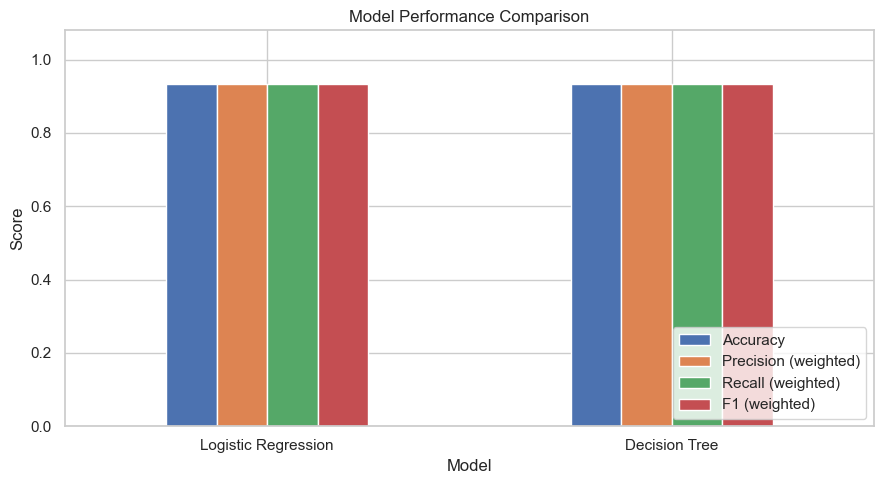

In [15]:
display(results_df.set_index("Model").style.format("{:.2%}"))
results_df.set_index("Model").plot(kind="bar", figsize=(9, 5), ylim=(0, 1.08), rot=0)
plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

,Column,Missing,Missing %,Unique values,Data type
0,sepal_length,0,0.0,35,float64
1,sepal_width,0,0.0,23,float64
2,petal_length,0,0.0,43,float64
3,petal_width,0,0.0,22,float64
4,species,0,0.0,3,object


Duplicate rows: 1
Class counts:


,Species,Count
0,setosa,50
1,versicolor,50
2,virginica,50


,IQR flagged rows
sepal_length,0
sepal_width,4
petal_length,0
petal_width,0


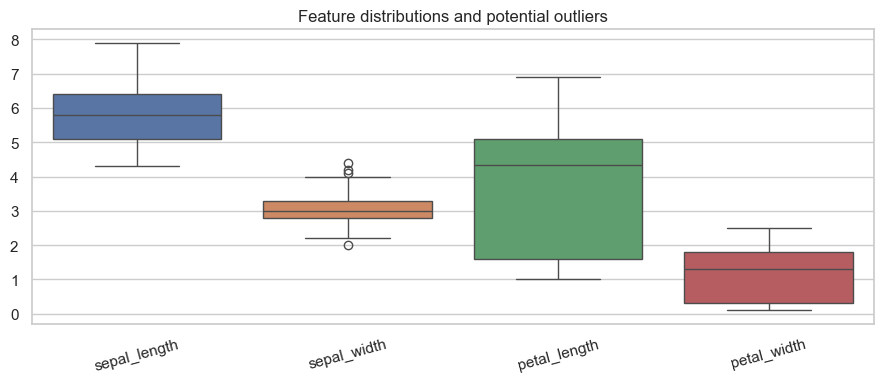

Class imbalance ratio (largest / smallest): 1.0


In [17]:
from sklearn.ensemble import IsolationForest
from IPython.display import display, Markdown
quality_report = pd.DataFrame({
    "Column": df.columns,
    "Missing": df.isna().sum().values,
    "Missing %": (df.isna().mean()*100).round(2).values,
    "Unique values": df.nunique().values,
    "Data type": df.dtypes.astype(str).values
})
display(quality_report)
print("Duplicate rows:", int(df.duplicated().sum()))
print("Class counts:")
display(df['species'].value_counts().rename_axis('Species').reset_index(name='Count'))
# IQR outlier flags are descriptive only; do not remove data automatically.
num_cols = X.columns.tolist()
q1, q3 = df[num_cols].quantile(.25), df[num_cols].quantile(.75)
iqr = q3 - q1
outlier_flags = ((df[num_cols] < (q1 - 1.5*iqr)) | (df[num_cols] > (q3 + 1.5*iqr)))
display(outlier_flags.sum().rename('IQR flagged rows').to_frame())
fig, ax = plt.subplots(figsize=(9,4))
sns.boxplot(data=df[num_cols], ax=ax)
ax.set_title('Feature distributions and potential outliers')
plt.xticks(rotation=15); plt.tight_layout(); plt.show()
print('Class imbalance ratio (largest / smallest):', round(df['species'].value_counts().max()/df['species'].value_counts().min(),2))

In [18]:
try:
    import plotly.express as px
    import ipywidgets as widgets
    from IPython.display import clear_output
    species_filter = widgets.Dropdown(options=['All']+sorted(df['species'].unique().tolist()), description='Species:')
    x_feature = widgets.Dropdown(options=num_cols, value='sepal_length', description='X axis:')
    y_feature = widgets.Dropdown(options=num_cols, value='petal_length', description='Y axis:')
    dashboard_output = widgets.Output()
    def update_dashboard(change=None):
        with dashboard_output:
            clear_output(wait=True)
            subset = df if species_filter.value=='All' else df[df['species']==species_filter.value]
            display(Markdown(f'**Records shown:** {len(subset)}'))
            fig = px.scatter(subset, x=x_feature.value, y=y_feature.value, color='species',
                             hover_data=num_cols, title='IrisVision AI — Explore Flowers')
            fig.show()
            px.histogram(subset, x=x_feature.value, color='species', marginal='box', title='Feature distribution').show()
    for control in (species_filter,x_feature,y_feature): control.observe(update_dashboard, names='value')
    display(widgets.VBox([widgets.HBox([species_filter,x_feature,y_feature]),dashboard_output]))
    update_dashboard()
except ImportError:
    print('For interactive dashboard run: %pip install plotly ipywidgets')
    sns.scatterplot(data=df,x='sepal_length',y='petal_length',hue='species');plt.show()

In [19]:
def predict_flower(sepal_length, sepal_width, petal_length, petal_width, model_name='Logistic Regression'):
    sample = pd.DataFrame([[sepal_length,sepal_width,petal_length,petal_width]], columns=X.columns)
    if model_name=='Logistic Regression':
        model, model_input = log_model, scaler.transform(sample)
    elif model_name=='Decision Tree':
        model, model_input = tree_model, sample
    else: raise ValueError('Unknown model')
    pred = model.predict(model_input)[0]
    probs = pd.Series(model.predict_proba(model_input)[0], index=model.classes_,name='Probability')
    return pred, probs
try:
    import ipywidgets as widgets
    sliders = [widgets.FloatSlider(value=v,min=lo,max=hi,step=.1,description=label,continuous_update=False,style={'description_width':'initial'})
               for label,v,lo,hi in [('Sepal length',5.1,3,9),('Sepal width',3.5,1,5),('Petal length',1.4,0,8),('Petal width',.2,0,3)]]
    model_picker = widgets.Dropdown(options=['Logistic Regression','Decision Tree'],description='Model:')
    predict_button = widgets.Button(description='Predict Flower',button_style='success',icon='check')
    prediction_output = widgets.Output()
    def on_predict_clicked(button):
        with prediction_output:
            clear_output(wait=True)
            species, probabilities = predict_flower(*[s.value for s in sliders], model_name=model_picker.value)
            display(Markdown(f'### Predicted species: **{species.title()}**'))
            display((probabilities*100).round(2).rename('Probability (%)').to_frame())
            probabilities.sort_values().plot.barh(figsize=(7,3),xlim=(0,1),title='Predicted class probabilities')
            plt.tight_layout();plt.show()
    predict_button.on_click(on_predict_clicked)
    display(widgets.VBox(sliders+[model_picker,predict_button,prediction_output]))
except ImportError:
    print('For interactive prediction run: %pip install ipywidgets')
    print('Example prediction:',predict_flower(5.1,3.5,1.4,.2))

,Model,Feature,Importance,Std
6,Decision Tree,petal_length,0.5017,0.0879
7,Decision Tree,petal_width,0.1017,0.0553
5,Decision Tree,sepal_width,0.0117,0.0159
4,Decision Tree,sepal_length,-0.0167,0.0167
3,Logistic Regression,petal_width,0.2117,0.0871
2,Logistic Regression,petal_length,0.1767,0.0559
1,Logistic Regression,sepal_width,0.0467,0.0400
0,Logistic Regression,sepal_length,0.0217,0.0159


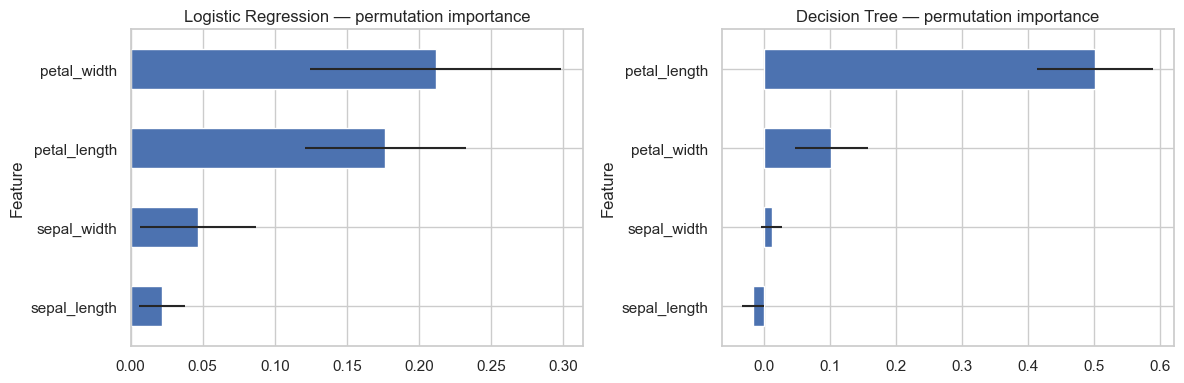

,Feature,Tree impurity importance
2,petal_length,0.558568
3,petal_width,0.406015
1,sepal_width,0.029167
0,sepal_length,0.006250


In [20]:
from sklearn.inspection import permutation_importance
importance_frames=[]
for name,model,model_input in [('Logistic Regression',log_model,X_test_scaled),('Decision Tree',tree_model,X_test)]:
    perm = permutation_importance(model,model_input,y_test,n_repeats=20,random_state=42,scoring='accuracy')
    for feature,mean,std in zip(X.columns,perm.importances_mean,perm.importances_std):
        importance_frames.append({'Model':name,'Feature':feature,'Importance':mean,'Std':std})
importance_df=pd.DataFrame(importance_frames)
display(importance_df.sort_values(['Model','Importance'],ascending=[True,False]).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,(name,group) in zip(axes,importance_df.groupby('Model',sort=False)):
    group.sort_values('Importance').plot.barh(x='Feature',y='Importance',xerr='Std',ax=ax,legend=False)
    ax.set_title(name+' — permutation importance')
plt.tight_layout();plt.show()
display(pd.DataFrame({'Feature':X.columns,'Tree impurity importance':tree_model.feature_importances_}).sort_values('Tree impurity importance',ascending=False))

,Model,CV Accuracy Mean,CV Accuracy Std,CV F1 Mean,CV Total Runtime (s)
0,Logistic Regression,0.9583,0.0264,0.9580,0.1164
1,Decision Tree,0.9500,0.0167,0.9496,0.0533


,Model,Accuracy,Precision (weighted),Recall (weighted),F1 (weighted)
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


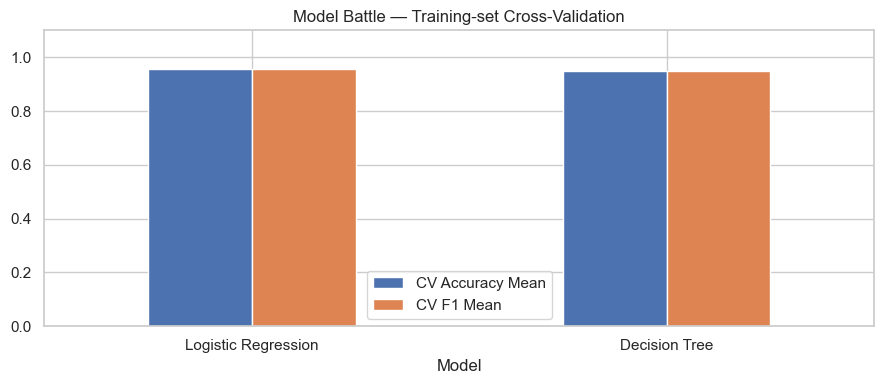

Highest mean cross-validation accuracy: Logistic Regression (ties may occur; consider simplicity and stability).


In [21]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from time import perf_counter
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
battle_rows=[]
for name,estimator in [('Logistic Regression',make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,random_state=42))),
                       ('Decision Tree',DecisionTreeClassifier(random_state=42))]:
    start=perf_counter()
    scores=cross_validate(estimator,X_train,y_train,cv=cv,scoring={'accuracy':'accuracy','f1_weighted':'f1_weighted'},n_jobs=1)
    duration=perf_counter()-start
    battle_rows.append({'Model':name,'CV Accuracy Mean':scores['test_accuracy'].mean(),
                        'CV Accuracy Std':scores['test_accuracy'].std(),
                        'CV F1 Mean':scores['test_f1_weighted'].mean(),
                        'CV Total Runtime (s)':duration})
battle_df=pd.DataFrame(battle_rows)
display(battle_df.round(4))
display(results_df.round(4))
ax=battle_df.plot.bar(x='Model',y=['CV Accuracy Mean','CV F1 Mean'],rot=0,ylim=(0,1.1),figsize=(9,4))
ax.set_title('Model Battle — Training-set Cross-Validation');plt.tight_layout();plt.show()
best=battle_df.loc[battle_df['CV Accuracy Mean'].idxmax(),'Model']
print('Highest mean cross-validation accuracy:',best,'(ties may occur; consider simplicity and stability).')

In [22]:
from pathlib import Path
excel_path=Path('IrisVision_AI_Results.xlsx')
prediction_report=X_test.copy()
prediction_report['Actual Species']=y_test
prediction_report['Logistic Regression Prediction']=log_pred
prediction_report['Decision Tree Prediction']=tree_pred
prediction_report['Logistic Correct']=prediction_report['Actual Species']==prediction_report['Logistic Regression Prediction']
prediction_report['Tree Correct']=prediction_report['Actual Species']==prediction_report['Decision Tree Prediction']
with pd.ExcelWriter(excel_path,engine='openpyxl') as writer:
    df.to_excel(writer,sheet_name='Iris Dataset',index=False)
    results_df.to_excel(writer,sheet_name='Test Metrics',index=False)
    prediction_report.to_excel(writer,sheet_name='Predictions',index=True,index_label='Original Row')
    quality_report.to_excel(writer,sheet_name='Data Quality',index=False)
    importance_df.to_excel(writer,sheet_name='Explainable AI',index=False)
    battle_df.to_excel(writer,sheet_name='Model Battle',index=False)
print('Excel report saved to:',excel_path.resolve())

Excel report saved to: C:\Users\rohan bhowmik\IrisVision_AI_Results.xlsx
